In [13]:
import numpy as np
import jax.numpy as jnp
import matplotlib.pyplot as plt
from scipy.integrate import odeint

In [14]:
def TodaLatt(w, t):
    
    p1, q1, p2, q2, p3, q3 = w

    p1_t = -jnp.exp(q1 - q2)
    q1_t = p1

    p2_t = jnp.exp(q1 - q2) - jnp.exp(q2 - q3)
    q2_t = p2

    p3_t = jnp.exp(q2 - q3)
    q3_t = p3

    dwdt = [p1_t, q1_t, p2_t, q2_t, p3_t, q3_t]

    return dwdt

In [15]:
t0, tfinal = 0.0, 1.0

In [16]:
n = 500
t = np.linspace(t0, tfinal, n)

p1_init = np.random.uniform(-1.0, 1.0, size=(1,))
q1_init = np.random.uniform(-1.0, 1.0, size=(1,))
p2_init = np.random.uniform(-1.0, 1.0, size=(1,))
q2_init = np.random.uniform(-1.0, 1.0, size=(1,))
p3_init = np.random.uniform(-1.0, 1.0, size=(1,))
q3_init = np.random.uniform(-1.0, 1.0, size=(1,))
H_init = (p1_init**2)/2 + (p2_init**2)/2 + (p3_init**2)/2 + jnp.exp(q1_init - q2_init) + jnp.exp(q2_init - q3_init)

data_rk = np.column_stack([p1_init, q1_init, p2_init, q2_init, p3_init, q3_init])
data_rk = np.reshape(data_rk, (-1,))
t_rk = t

sol_rk = odeint(TodaLatt, data_rk, t_rk\
                # , rtol = 1e-13, atol = 1e-13\
               )
p1_rk, q1_rk, p2_rk, q2_rk, p3_rk, q3_rk = sol_rk[:, 0], sol_rk[:, 1], sol_rk[:, 2], sol_rk[:, 3], sol_rk[:, 4], sol_rk[:, 5]
H_rk = (p1_rk**2)/2 + (p2_rk**2)/2 + (p3_rk**2)/2 + jnp.exp(q1_rk - q2_rk) + jnp.exp(q2_rk - q3_rk)

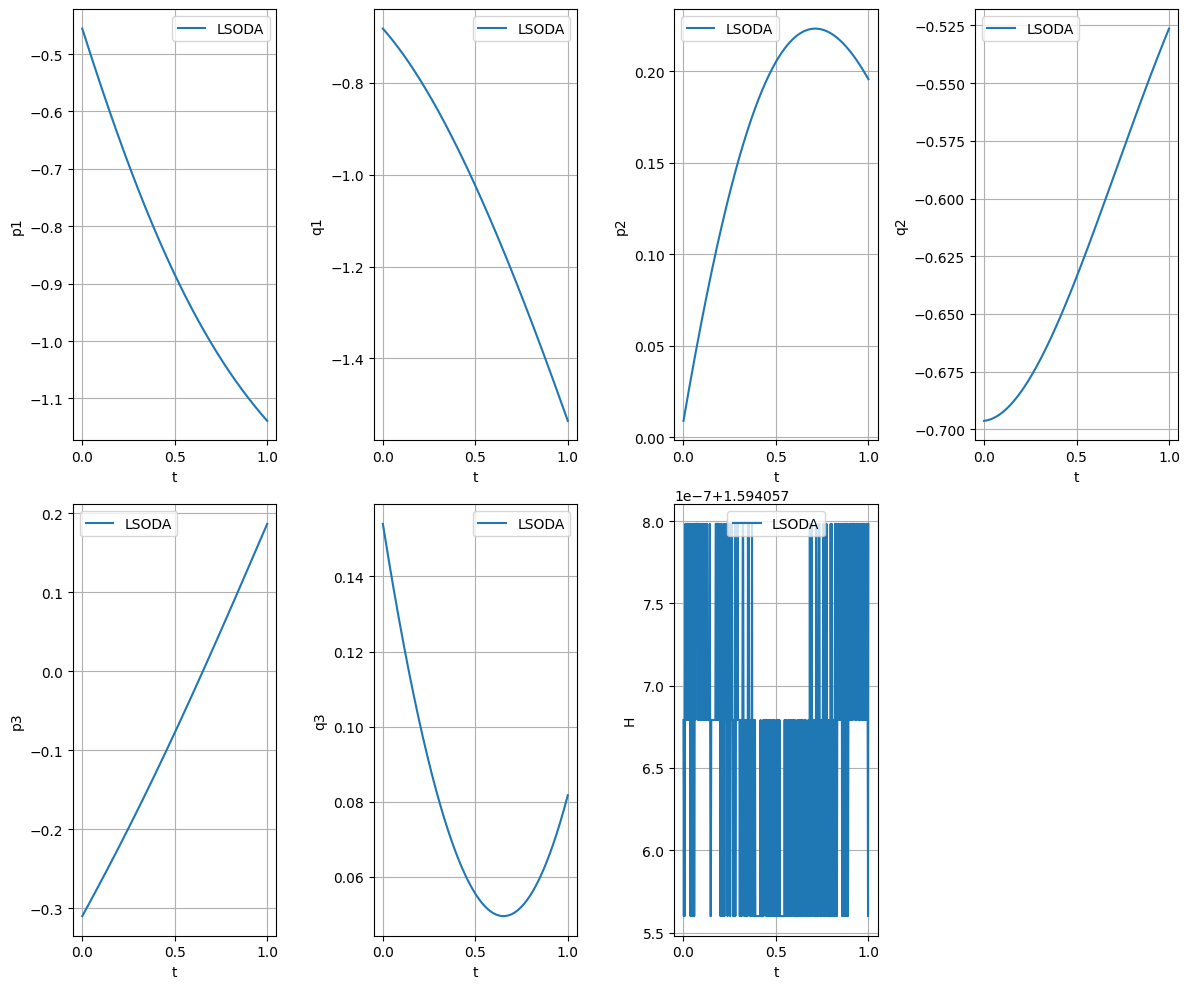

In [18]:
fig = plt.figure(figsize=(12, 10))

plt.subplot(2, 4, 1)
plt.tight_layout()
plt.plot(t, p1_rk, label = 'LSODA')
plt.xlabel("t")
plt.ylabel("p1")
plt.grid()
plt.legend()

plt.subplot(2, 4, 2)
plt.tight_layout()
plt.plot(t, q1_rk, label = 'LSODA')
plt.xlabel("t")
plt.ylabel("q1")
plt.grid()
plt.legend()

plt.subplot(2, 4, 3)
plt.tight_layout()
plt.plot(t, p2_rk, label = 'LSODA')
plt.xlabel("t")
plt.ylabel("p2")
plt.grid()
plt.legend()

plt.subplot(2, 4, 4)
plt.tight_layout()
plt.plot(t, q2_rk, label = 'LSODA')
plt.xlabel("t")
plt.ylabel("q2")
plt.grid()
plt.legend()

plt.subplot(2, 4, 5)
plt.tight_layout()
plt.plot(t, p3_rk, label = 'LSODA')
plt.xlabel("t")
plt.ylabel("p3")
plt.grid()
plt.legend()

plt.subplot(2, 4, 6)
plt.tight_layout()
plt.plot(t, q3_rk, label = 'LSODA')
plt.xlabel("t")
plt.ylabel("q3")
plt.grid()
plt.legend()

plt.subplot(2, 4, 7)
plt.tight_layout()
plt.plot(t, H_rk, label = 'LSODA')
plt.xlabel("t")
plt.ylabel("H")
plt.grid()
plt.legend()